In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks, peak_widths

ROOT = Path.cwd()
if not (ROOT / "asd_finite_temperature").exists():
    ROOT = Path("/home/senji77/akhyar/research/notebooks/ANSW")

INPUT = ROOT / "asd_finite_temperature"
OUTPUT = ROOT / "asd_final_analysis"
OUTPUT.mkdir(parents=True, exist_ok=True)

FILES = {
    0.1: ROOT / "asd_2d_results" / "asd_dynamical_structure_factor_T0p1.npz",
    0.3: INPUT / "asd_dynamical_structure_factor_T0p3.npz",
    0.5: INPUT / "asd_dynamical_structure_factor_T0p5.npz",
    1.0: INPUT / "asd_dynamical_structure_factor_T1p0.npz"
}

MODELS = [("dmi", "DMI-x", "#C00032"), ("frustration", "Frustration", "#0055CC")]
DATA = {}

for temperature, path in FILES.items():
    if not path.exists():
        print("Not found, skipped:", path)
        continue

    with np.load(path) as source:
        data = {key: source[key].copy() for key in source.files}

    data["qx"] = np.asarray(data["qx"], dtype=float)
    data["qy"] = np.asarray(data["qy"], dtype=float)
    data["omega"] = np.asarray(data["omega"], dtype=float)
    data["S_dmi"] = np.asarray(data["S_dmi"], dtype=np.float64)
    data["S_frustration"] = np.asarray(data["S_frustration"], dtype=np.float64)

    for key in ("S_dmi", "S_frustration"):
        assert data[key].shape == (len(data["omega"]), len(data["qx"]), len(data["qy"]))

    assert np.isclose(float(data["temperature"]), temperature)
    DATA[temperature] = data

TEMPERATURES = sorted(DATA)
assert TEMPERATURES, "No ASD data found"

for temperature in TEMPERATURES:
    d = DATA[temperature]
    dw = d["omega"][1] - d["omega"][0]
    print(f"T={temperature:.1f} | omega resolution={dw:.6f} | replicas={int(d['n_replicas'])} | shape={d['S_dmi'].shape}")

print("Output:", OUTPUT)

T=0.1 | omega resolution=0.098175 | replicas=4 | shape=(256, 64, 64)
T=0.3 | omega resolution=0.098175 | replicas=4 | shape=(256, 64, 64)
T=0.5 | omega resolution=0.098175 | replicas=4 | shape=(256, 64, 64)
T=1.0 | omega resolution=0.098175 | replicas=4 | shape=(256, 64, 64)
Output: /home/senji77/akhyar/research/notebooks/ANSW/asd_final_analysis


In [2]:
q0 = np.pi / 4
J = float(DATA[TEMPERATURES[0]]["J"])
D = float(DATA[TEMPERATURES[0]]["D"])
J2 = float(DATA[TEMPERATURES[0]]["J2"])

for t in TEMPERATURES[1:]:
    assert np.isclose(float(DATA[t]["J"]), J)
    assert np.isclose(float(DATA[t]["D"]), D)
    assert np.isclose(float(DATA[t]["J2"]), J2)
    assert np.allclose(DATA[t]["qx"], DATA[TEMPERATURES[0]]["qx"])
    assert np.allclose(DATA[t]["qy"], DATA[TEMPERATURES[0]]["qy"])

def lswt_2d(kx, ky, model):
    cq = np.cos(q0)
    cx = np.cos(kx)
    cy = np.cos(ky)
    if model == "dmi":
        lam = 2 * J * (1 + cq) + 2 * D * np.sin(q0)
        A = lam - 2 * J * (cx + cy)
        B = lam - 2 * ((J * cq + D * np.sin(q0)) * cx + J * cy)
    else:
        lam = 2 * J * (1 + cq) - 2 * J2 * np.cos(2 * q0)
        A = lam - 2 * J * (cx + cy) + 2 * J2 * np.cos(2 * kx)
        B = lam - 2 * J * (cq * cx + cy) + 2 * J2 * np.cos(2 * q0) * np.cos(2 * kx)
    return np.sqrt(np.maximum(A * B, 0))

def candidates_lab(kx, ky, model):
    return {
        "unshifted": float(lswt_2d(kx, ky, model)),
        "minus_q0": float(lswt_2d(kx - q0, ky, model)),
        "plus_q0": float(lswt_2d(kx + q0, ky, model))
    }

OMEGA_MAX = 8.0
qvalues = [0.0, np.pi / 4]
all_values = []
for t in TEMPERATURES:
    d = DATA[t]
    for model, _, _ in MODELS:
        iy = np.argmin(np.abs(d["qy"]))
        valid = d["omega"] <= OMEGA_MAX
        all_values.append(d[f"S_{model}"][valid, :, iy])

positive_values = np.concatenate([x[x > 0] for x in all_values])
GLOBAL_MAX = float(max(x.max() for x in all_values))
GLOBAL_FLOOR = max(GLOBAL_MAX * 1e-5, np.finfo(float).tiny)
print("Common color scale:", GLOBAL_FLOOR, GLOBAL_MAX)

Common color scale: 0.0041738159179687505 417.381591796875


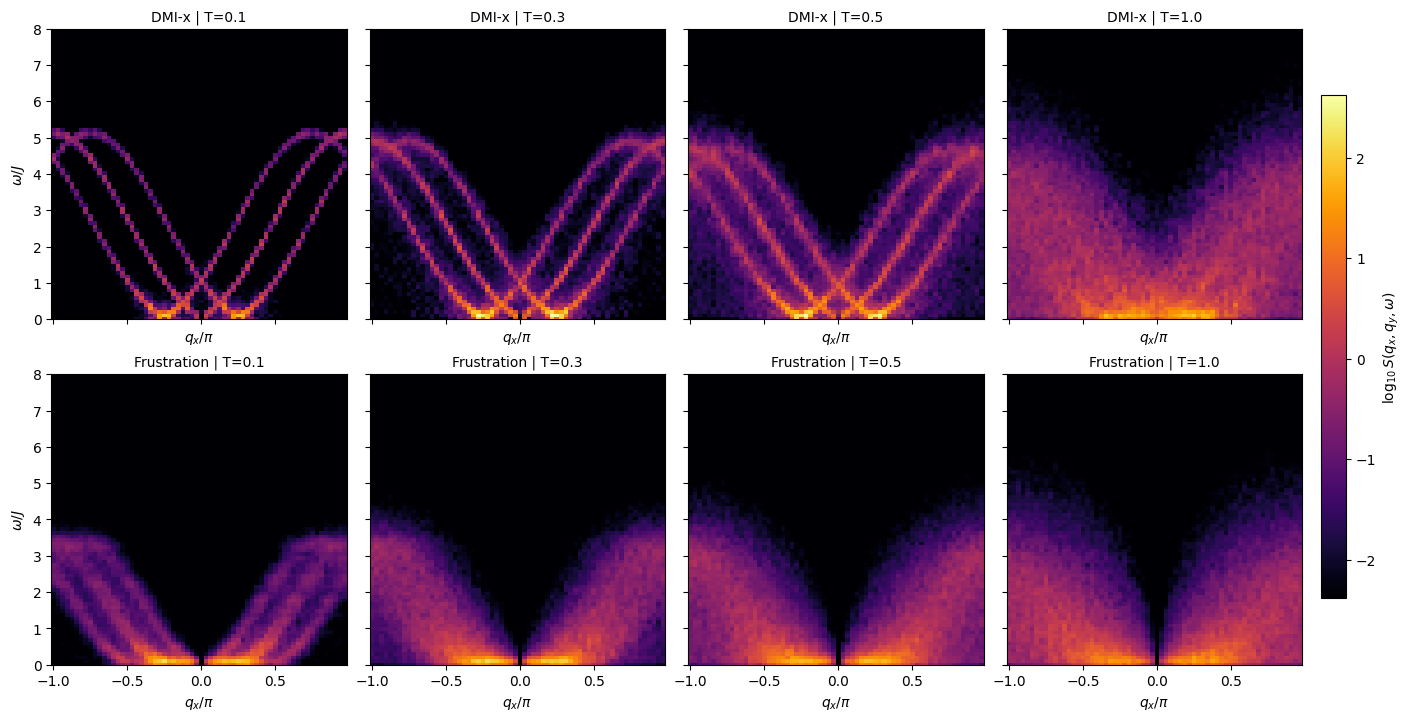

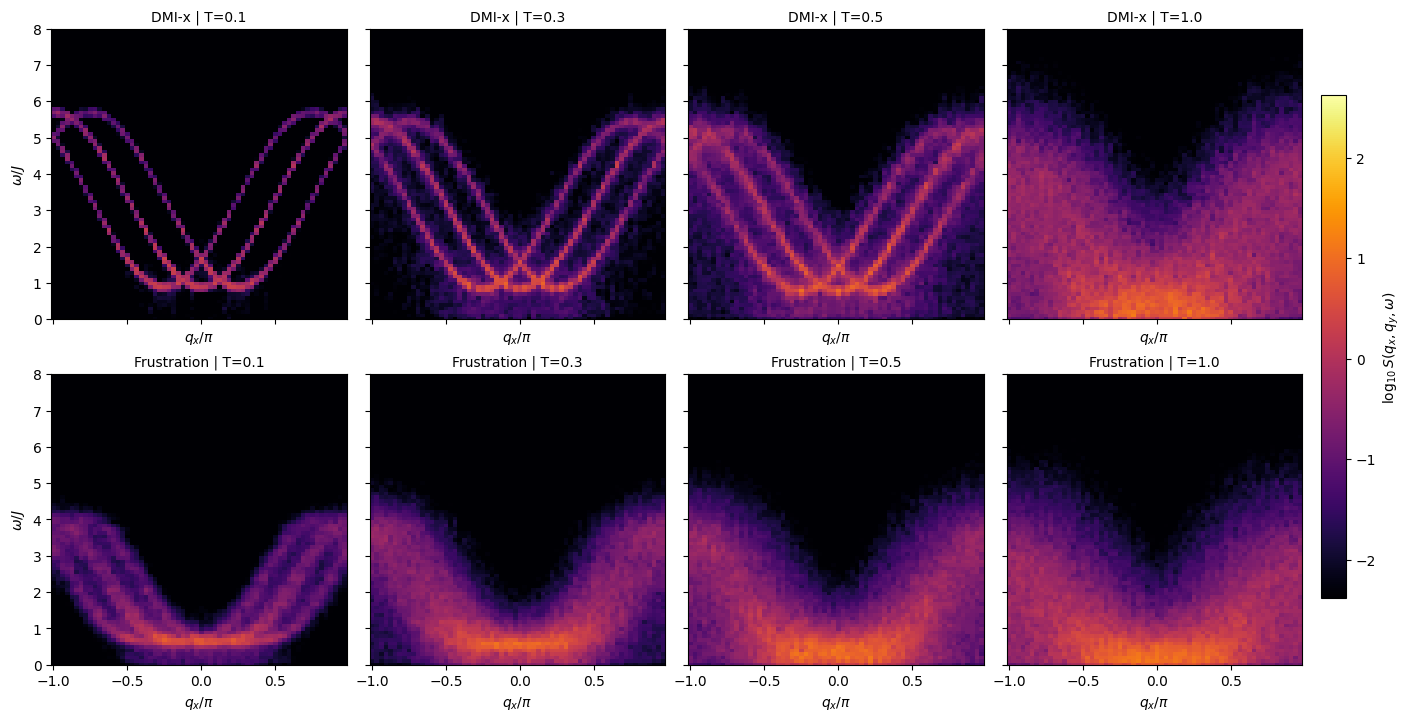

In [3]:
for ky_target in qvalues:
    fig, axes = plt.subplots(
        2, len(TEMPERATURES),
        figsize=(3.35 * len(TEMPERATURES) + 0.6, 7.1),
        sharex=True, sharey=True, constrained_layout=True,
        squeeze=False
    )
    for col, t in enumerate(TEMPERATURES):
        d = DATA[t]
        iy = np.argmin(np.abs(d["qy"] - ky_target))
        valid = d["omega"] <= OMEGA_MAX
        for row, (model, name, _) in enumerate(MODELS):
            ax = axes[row, col]
            spectrum = d[f"S_{model}"][valid, :, iy]
            im = ax.pcolormesh(
                d["qx"] / np.pi,
                d["omega"][valid],
                np.log10(np.maximum(spectrum, GLOBAL_FLOOR)),
                shading="auto", cmap="inferno",
                vmin=np.log10(GLOBAL_FLOOR), vmax=np.log10(GLOBAL_MAX)
            )
            ax.set_title(f"{name} | T={t:.1f}", fontsize=10)
            ax.set_xlabel(r"$q_x/\pi$")
            ax.set_ylim(0, OMEGA_MAX)
            if col == 0:
                ax.set_ylabel(r"$\omega/J$")

    fig.colorbar(im, ax=axes, shrink=0.79, pad=0.015, label=r"$\log_{10}S(q_x,q_y,\omega)$")
    tag = str(round(ky_target / np.pi, 2)).replace(".", "p")
    fig.savefig(OUTPUT / f"spectra_qy_pi_{tag}.pdf", bbox_inches="tight")
    fig.savefig(OUTPUT / f"spectra_qy_pi_{tag}.png", dpi=300, bbox_inches="tight")
    plt.show()

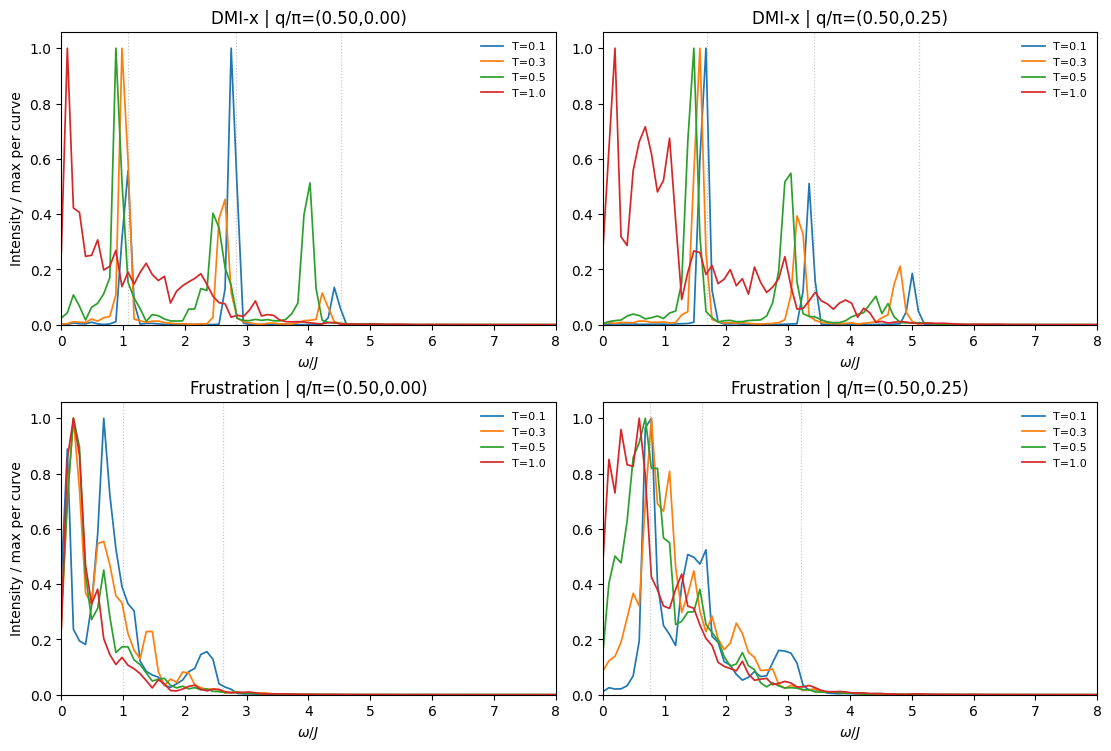

In [4]:
Q_TARGETS = [(np.pi / 2, 0.0), (np.pi / 2, np.pi / 4)]

fig, axes = plt.subplots(2, 2, figsize=(11, 7.4), constrained_layout=True)
for row, (model, name, color) in enumerate(MODELS):
    for col, (kx_target, ky_target) in enumerate(Q_TARGETS):
        ax = axes[row, col]
        for t in TEMPERATURES:
            d = DATA[t]
            ix = np.argmin(np.abs(d["qx"] - kx_target))
            iy = np.argmin(np.abs(d["qy"] - ky_target))
            profile = d[f"S_{model}"][:, ix, iy]
            scale = max(float(profile.max()), 1e-25)
            ax.plot(d["omega"], profile / scale, lw=1.25, label=f"T={t:.1f}")
        for theory in candidates_lab(kx_target, ky_target, model).values():
            if 0 < theory < OMEGA_MAX:
                ax.axvline(theory, color="gray", ls=":", lw=0.85, alpha=0.45)
        ax.set_xlim(0, OMEGA_MAX)
        ax.set_ylim(0, 1.06)
        ax.set_title(f"{name} | q/π=({kx_target/np.pi:.2f},{ky_target/np.pi:.2f})")
        ax.set_xlabel(r"$\omega/J$")
        if col == 0:
            ax.set_ylabel("Intensity / max per curve")
        ax.legend(frameon=False, fontsize=8)
fig.savefig(OUTPUT / "normalized_peak_profiles.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "normalized_peak_profiles.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
def extract_peaks(d, model, kx_target, ky_target, sigma_bins=0.6):
    qx = d["qx"]
    qy = d["qy"]
    omega = d["omega"]
    ix = np.argmin(np.abs(qx - kx_target))
    iy = np.argmin(np.abs(qy - ky_target))
    mask = (omega >= 0.25) & (omega <= OMEGA_MAX)
    w = omega[mask]
    spectrum = d[f"S_{model}"][mask, ix, iy]
    smooth = gaussian_filter1d(spectrum, sigma=sigma_bins)
    relative = smooth / max(float(smooth.max()), 1e-25)
    spacing = float(np.median(np.diff(w)))
    peaks, properties = find_peaks(relative, prominence=0.08, height=0.1, distance=2)
    widths = peak_widths(relative, peaks, rel_height=0.5)[0] * spacing if len(peaks) else np.empty(0)
    return float(qx[ix]), float(qy[iy]), w, relative, peaks, widths, properties, spacing

peak_rows = []
branch_rows = []

for t in TEMPERATURES:
    d = DATA[t]
    for model, name, _ in MODELS:
        for kx_target, ky_target in Q_TARGETS:
            kx, ky, w, signal, peaks, widths, props, spacing = extract_peaks(d, model, kx_target, ky_target)
            theories = candidates_lab(kx, ky, model)
            local_peaks = []
            for j, index in enumerate(peaks):
                local_peaks.append((float(w[index]), float(signal[index]), float(widths[j]), float(props["prominences"][j])))
                peak_rows.append({
                    "T": t, "model": name, "qx_pi": kx/np.pi, "qy_pi": ky/np.pi,
                    "omega_peak": float(w[index]), "relative_height": float(signal[index]),
                    "prominence": float(props["prominences"][j]),
                    "apparent_width": float(widths[j]), "frequency_resolution": spacing
                })
            threshold = max(3 * spacing, 0.35)
            matches = {}
            for branch, prediction in theories.items():
                if len(peaks) == 0 or not (0.25 <= prediction <= OMEGA_MAX):
                    continue
                distances = np.abs(w[peaks] - prediction)
                closest = int(np.argmin(distances))
                if distances[closest] > threshold:
                    continue
                peak_id = int(peaks[closest])
                matches[branch] = peak_id
            counts = {p: sum(value == p for value in matches.values()) for p in matches.values()}
            for branch, peak_id in matches.items():
                j = int(np.where(peaks == peak_id)[0][0])
                branch_rows.append({
                    "T": t, "model": name, "qx_pi": kx/np.pi, "qy_pi": ky/np.pi,
                    "branch": branch, "omega_LSWT": theories[branch],
                    "omega_observed": float(w[peak_id]),
                    "frequency_shift": float(w[peak_id] - theories[branch]),
                    "apparent_width": float(widths[j]),
                    "relative_height": float(signal[peak_id]),
                    "ambiguous_peak": counts[peak_id] > 1
                })
            if not len(local_peaks):
                print(f"No robust peaks: T={t} {name}, q/pi=({kx/np.pi:.2f},{ky/np.pi:.2f})")

for filename, rows, fieldnames in [
    ("all_spectral_peaks.csv", peak_rows, ["T", "model", "qx_pi", "qy_pi", "omega_peak", "relative_height", "prominence", "apparent_width", "frequency_resolution"]),
    ("lswt_assigned_peaks.csv", branch_rows, ["T", "model", "qx_pi", "qy_pi", "branch", "omega_LSWT", "omega_observed", "frequency_shift", "apparent_width", "relative_height", "ambiguous_peak"])
]:
    with open(OUTPUT / filename, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

print("Detected peaks:", len(peak_rows))
print("LSWT candidate matches:", len(branch_rows))
for row in branch_rows:
    if row["qy_pi"] == 0:
        print(f"T={row['T']:.1f} {row['model']:12s} {row['branch']:10s} omega={row['omega_observed']:.4f} theory={row['omega_LSWT']:.4f} width={row['apparent_width']:.4f} ambiguous={row['ambiguous_peak']}")

No robust peaks: T=1.0 Frustration, q/pi=(0.50,0.00)
Detected peaks: 38
LSWT candidate matches: 29
T=0.1 DMI-x        unshifted  omega=2.7489 theory=2.8284 width=0.1976 ambiguous=False
T=0.1 DMI-x        minus_q0   omega=1.0799 theory=1.0824 width=0.2059 ambiguous=False
T=0.1 DMI-x        plus_q0    omega=4.4179 theory=4.5261 width=0.1970 ambiguous=False
T=0.1 Frustration  unshifted  omega=0.6872 theory=1.0000 width=0.3217 ambiguous=False
T=0.1 Frustration  plus_q0    omega=2.3562 theory=2.6131 width=0.3919 ambiguous=False
T=0.3 DMI-x        unshifted  omega=2.6507 theory=2.8284 width=0.2360 ambiguous=False
T=0.3 DMI-x        minus_q0   omega=0.9817 theory=1.0824 width=0.2060 ambiguous=False
T=0.3 DMI-x        plus_q0    omega=4.2215 theory=4.5261 width=0.2125 ambiguous=False
T=0.3 Frustration  unshifted  omega=0.6872 theory=1.0000 width=0.2470 ambiguous=False
T=0.5 DMI-x        minus_q0   omega=0.8836 theory=1.0824 width=0.2132 ambiguous=False
T=0.5 Frustration  unshifted  omega=0.687

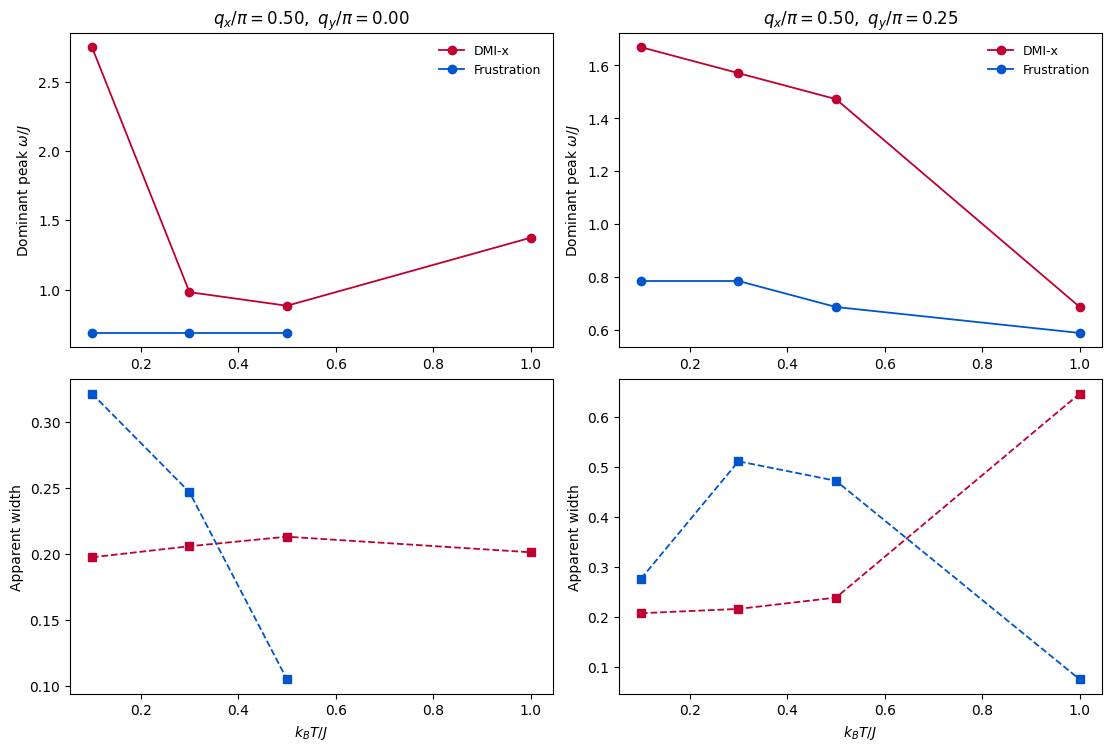

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.4), constrained_layout=True)
for col, (kx_target, ky_target) in enumerate(Q_TARGETS):
    for model, name, color in MODELS:
        rows = [r for r in peak_rows if r["model"] == name and np.isclose(r["qy_pi"], ky_target / np.pi)]
        dominant = []
        for t in TEMPERATURES:
            found = [r for r in rows if np.isclose(r["T"], t)]
            dominant.append(max(found, key=lambda r: r["relative_height"]) if found else None)
        x = np.array([r["T"] for r in dominant if r is not None])
        y_frequency = np.array([r["omega_peak"] for r in dominant if r is not None])
        y_width = np.array([r["apparent_width"] for r in dominant if r is not None])
        axes[0, col].plot(x, y_frequency, "o-", color=color, lw=1.3, label=name)
        axes[1, col].plot(x, y_width, "s--", color=color, lw=1.3, label=name)

    axes[0, col].set_title(rf"$q_x/\pi={kx_target/np.pi:.2f},\ q_y/\pi={ky_target/np.pi:.2f}$")
    axes[0, col].set_ylabel(r"Dominant peak $\omega/J$")
    axes[1, col].set_ylabel("Apparent width")
    axes[1, col].set_xlabel(r"$k_B T/J$")
    axes[0, col].legend(frameon=False, fontsize=9)

fig.savefig(OUTPUT / "dominant_peak_and_width_vs_temperature.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "dominant_peak_and_width_vs_temperature.png", dpi=300, bbox_inches="tight")
plt.show()

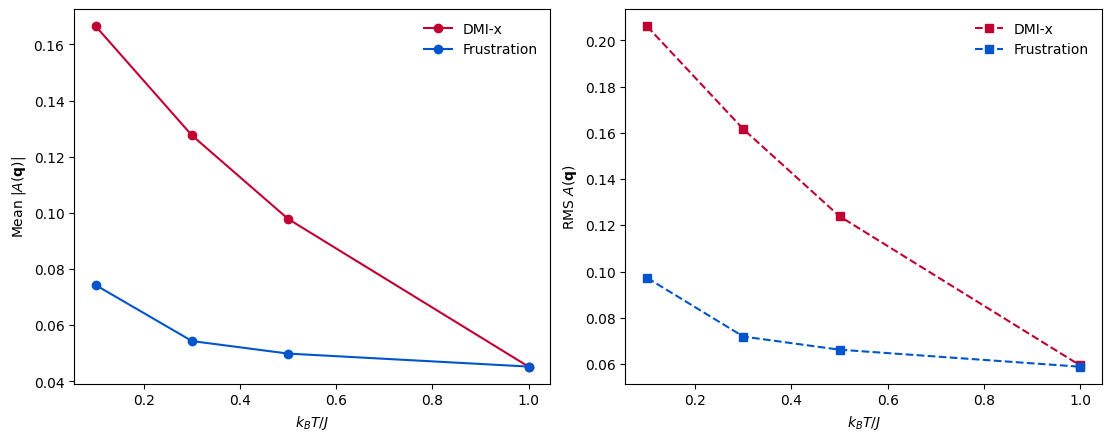

In [7]:
analysis_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
for model, name, color in MODELS:
    for t in TEMPERATURES:
        d = DATA[t]
        omega = d["omega"]
        mask = (omega >= 0.3) & (omega <= OMEGA_MAX)
        S = d[f"S_{model}"][mask]
        I = np.trapezoid(S, omega[mask], axis=0)
        rev_x = (-np.arange(len(d["qx"]))) % len(d["qx"])
        rev_y = (-np.arange(len(d["qy"]))) % len(d["qy"])
        I_reverse = I[np.ix_(rev_x, rev_y)]
        noise_floor = max(float(I.max()) * 1e-8, 1e-30)
        asym = (I - I_reverse) / (I + I_reverse + noise_floor)
        strong = (I + I_reverse) > 0.04 * np.max(I + I_reverse)
        mean_abs_asym = float(np.mean(np.abs(asym[strong]))) if np.any(strong) else np.nan
        rms_asym = float(np.sqrt(np.mean(asym[strong] ** 2))) if np.any(strong) else np.nan
        analysis_rows.append({"T": t, "model": name, "mean_absolute_intensity_asymmetry": mean_abs_asym, "rms_intensity_asymmetry": rms_asym})
    local = [r for r in analysis_rows if r["model"] == name]
    axes[0].plot([r["T"] for r in local], [r["mean_absolute_intensity_asymmetry"] for r in local], "o-", color=color, label=name)
    axes[1].plot([r["T"] for r in local], [r["rms_intensity_asymmetry"] for r in local], "s--", color=color, label=name)

axes[0].set_ylabel(r"Mean $|A(\mathbf{q})|$")
axes[1].set_ylabel(r"RMS $A(\mathbf{q})$")
for ax in axes:
    ax.set_xlabel(r"$k_BT/J$")
    ax.legend(frameon=False)
fig.savefig(OUTPUT / "integrated_intensity_asymmetry_vs_temperature.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "integrated_intensity_asymmetry_vs_temperature.png", dpi=300, bbox_inches="tight")
plt.show()

with open(OUTPUT / "integrated_asymmetry.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["T", "model", "mean_absolute_intensity_asymmetry", "rms_intensity_asymmetry"])
    writer.writeheader()
    writer.writerows(analysis_rows)

T=0.1 DMI-x        maximum energy drift=2.2687e-05
T=0.3 DMI-x        maximum energy drift=4.9984e-05
T=0.5 DMI-x        maximum energy drift=6.1285e-05
T=1.0 DMI-x        maximum energy drift=4.5612e-05
T=0.1 Frustration  maximum energy drift=6.6763e-06
T=0.3 Frustration  maximum energy drift=1.3927e-05
T=0.5 Frustration  maximum energy drift=1.5554e-05
T=1.0 Frustration  maximum energy drift=1.4232e-05


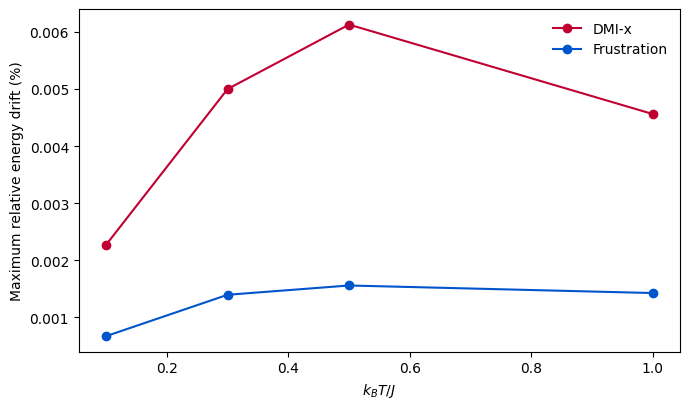

Files saved in: /home/senji77/akhyar/research/notebooks/ANSW/asd_final_analysis


In [8]:
energy_rows = []
fig, ax = plt.subplots(figsize=(7, 4.2))
for model, name, color in MODELS:
    t_axis = []
    drifts = []
    for t in TEMPERATURES:
        d = DATA[t]
        energies = np.asarray(d[f"energy_{model}"], dtype=float)
        relative = np.abs(energies - energies[0]) / np.maximum(np.abs(energies[0]), 1e-10)
        drift = float(np.max(relative))
        energy_rows.append({"T": t, "model": name, "max_relative_energy_drift": drift, "replicas": int(d["n_replicas"])})
        t_axis.append(t)
        drifts.append(drift)
        print(f"T={t:.1f} {name:12s} maximum energy drift={drift:.4e}")
    ax.plot(t_axis, np.array(drifts) * 100, "o-", color=color, label=name)

ax.set_xlabel(r"$k_BT/J$")
ax.set_ylabel("Maximum relative energy drift (%)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT / "asd_energy_drift_vs_temperature.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "asd_energy_drift_vs_temperature.png", dpi=300, bbox_inches="tight")
plt.show()

with open(OUTPUT / "asd_energy_drift.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["T", "model", "max_relative_energy_drift", "replicas"])
    writer.writeheader()
    writer.writerows(energy_rows)

print("Files saved in:", OUTPUT.resolve())